# 01 - Exploration des données (EDA)

**Objectif du projet** : classifier une IRM cérébrale en 4 catégories : *glioma*, *meningioma*, *pituitary*, *notumor*.

**Dataset** : [Brain Tumor MRI Dataset (Kaggle)](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset)

Ce notebook répond à la 1re partie de l'étape 1 du sujet : **explorer le dataset**

In [1]:
# eviter le reload de kernel

%load_ext autoreload
%autoreload 2

In [2]:
# imports
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# pour placer les figures 

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
from load_data import CLASS_NAMES, list_images, load_brain_tumor_data
import hashlib

from sklearn.decomposition import PCA


## 1. Chargement
Le dataset est téléchargé via `kagglehub` (mis en cache localement après le 1er téléchargement).

In [3]:
DATA = load_brain_tumor_data()
rows = []
for split in ["Training", "Testing"]:
    paths, labels = list_images(DATA, split)
    for p, y in zip(paths, labels):
        rows.append({"split": split, "classe": CLASS_NAMES[y], "path": p})
df = pd.DataFrame(rows)
print(DATA)
df.head()

C:\Users\araba\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\araba\.cache\kagglehub\datasets\masoudnickparvar\brain-tumor-mri-dataset\versions\2


,split,classe,path
0,Training,glioma,C:\Users\araba\.cache\kagglehub\datasets\masou...
1,Training,glioma,C:\Users\araba\.cache\kagglehub\datasets\masou...
2,Training,glioma,C:\Users\araba\.cache\kagglehub\datasets\masou...
3,Training,glioma,C:\Users\araba\.cache\kagglehub\datasets\masou...
4,Training,glioma,C:\Users\araba\.cache\kagglehub\datasets\masou...


In [4]:
df.shape # toujours verifier sa dim

(7200, 3)

## 2. Répartition des classes

split,Testing,Training,Total
classe,,,
glioma,400,1400,1800
meningioma,400,1400,1800
notumor,400,1400,1800
pituitary,400,1400,1800


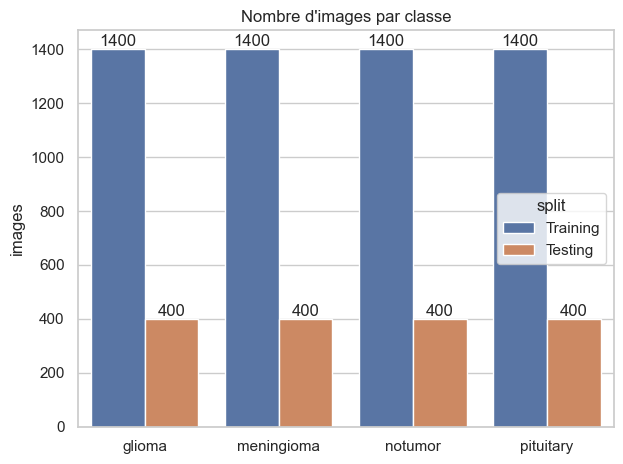

In [5]:
counts = df.pivot_table(index="classe", columns="split", values="path", aggfunc="count")
counts["Total"] = counts.sum(axis=1)
display(counts)

ax = sns.countplot(data=df, x="classe", hue="split", order=CLASS_NAMES)
ax.set(title="Nombre d'images par classe", xlabel="", ylabel="images")
for c in ax.containers:
    ax.bar_label(c)
plt.tight_layout(); plt.savefig(FIG / "eda_class_distribution.png", dpi=150); plt.show()

**Constat** : le dataset est **parfaitement équilibré** (1 400 images par classe en Training, 400 en Testing).
- Pas besoin de pondérer la loss ni de sur-échantillonner.
- L'*accuracy* est donc une métrique pertinente (une classe ne peut pas « gonfler » le score).

Attention : ça ne tient plus après le nettoyage des doublons (notebook 02), notumor perd beaucoup d'images.

## 3. Format et taille des images

In [6]:
def info(p):
    im = Image.open(p)
    return pd.Series({"largeur": im.width, "hauteur": im.height, "mode": im.mode})

df = pd.concat([df, df["path"].apply(info)], axis=1)
print("Modes couleur :", df["mode"].value_counts().to_dict())
print("Nombre de tailles différentes :", df.groupby(["largeur", "hauteur"]).ngroups)
display(df[["largeur", "hauteur"]].describe().round(0))
display(df.groupby(["largeur", "hauteur"]).size().sort_values(ascending=False).head(5).rename("images"))

Modes couleur : {'RGB': 4129, 'L': 3067, 'RGBA': 3, 'P': 1}
Nombre de tailles différentes : 447


,largeur,hauteur
count,7200.0,7200.0
mean,453.0,457.0
std,130.0,124.0
min,150.0,167.0
25%,442.0,449.0
50%,512.0,512.0
75%,512.0,512.0
max,1375.0,1446.0


largeur  hauteur
512      512        5014
225      225         338
630      630          90
201      251          57
228      221          51
Name: images, dtype: int64

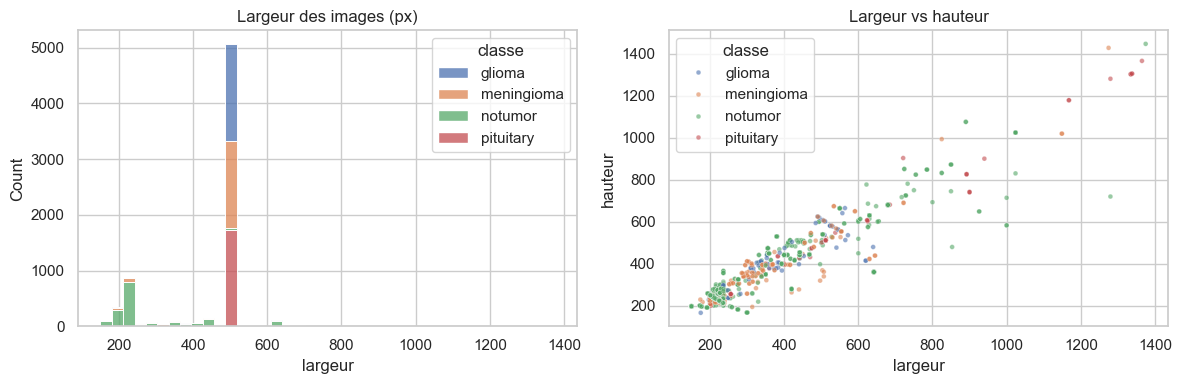

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df, x="largeur", hue="classe", bins=40, ax=axes[0], multiple="stack")
axes[0].set_title("Largeur des images (px)")
sns.scatterplot(df, x="largeur", y="hauteur", hue="classe", s=12, alpha=0.6, ax=axes[1])
axes[1].set_title("Largeur vs hauteur")
plt.tight_layout(); plt.savefig(FIG / "eda_image_sizes.png", dpi=150); plt.show()

**Constats** :
- **~450 tailles différentes**, de ~150 px à ~1 400 px ; la grande majorité fait **512×512**. Certaines ne sont pas carrées.
  → il faut **redimensionner à une taille fixe** (un CNN a besoin d'entrées de même taille).
- Les fichiers sont enregistrés dans des modes mélangés (`L` = niveaux de gris, `RGB` = couleur, quelques `RGBA`/`P`). Le mode dit seulement **comment le fichier est stocké**, pas ce qu'il contient : on regarde les images juste en dessous pour trancher.

In [8]:
df["ratio"] = df["largeur"] / df["hauteur"]
df["carree"] = df["largeur"] == df["hauteur"]
df["taille_ko"] = df["path"].apply(lambda p: Path(p).stat().st_size / 1024)
df["std512"] = (df["largeur"] == 512) & (df["hauteur"] == 512)

In [9]:
# mode et taille standard par classe (en % de la classe)
display(pd.crosstab(df["classe"], df["mode"], normalize="index").mul(100).round(1))
display(df.groupby("classe")[["carree", "std512"]].mean().mul(100).round(1))
display(df.groupby("classe")[["ratio", "taille_ko"]].describe().round(2).T)

mode,L,P,RGB,RGBA
classe,,,,
glioma,77.7,0.0,22.3,0.0
meningioma,39.4,0.0,60.6,0.0
notumor,1.6,0.1,98.2,0.2
pituitary,51.7,0.0,48.3,0.0


,carree,std512
classe,,
glioma,96.4,95.8
meningioma,88.2,86.1
notumor,32.2,1.1
pituitary,98.1,95.6


classe            glioma  meningioma  notumor  pituitary
ratio     count  1800.00     1800.00  1800.00    1800.00
          mean      1.00        0.99     0.97       1.00
          std       0.03        0.06     0.17       0.01
          min       0.78        0.73     0.64       0.80
          25%       1.00        1.00     0.86       1.00
          50%       1.00        1.00     1.00       1.00
          75%       1.00        1.00     1.00       1.00
          max       1.49        1.61     1.79       1.21
taille_ko count  1800.00     1800.00  1800.00    1800.00
          mean     19.71       21.86    19.64      29.85
          std       5.52        8.76    21.69      19.14
          min       7.99        4.80     3.59      10.37
          25%      16.28       17.93     8.64      24.44
          50%      18.94       21.34    12.10      27.66
          75%      22.02       24.99    22.02      32.12
          max      70.21      227.59   299.31     262.51

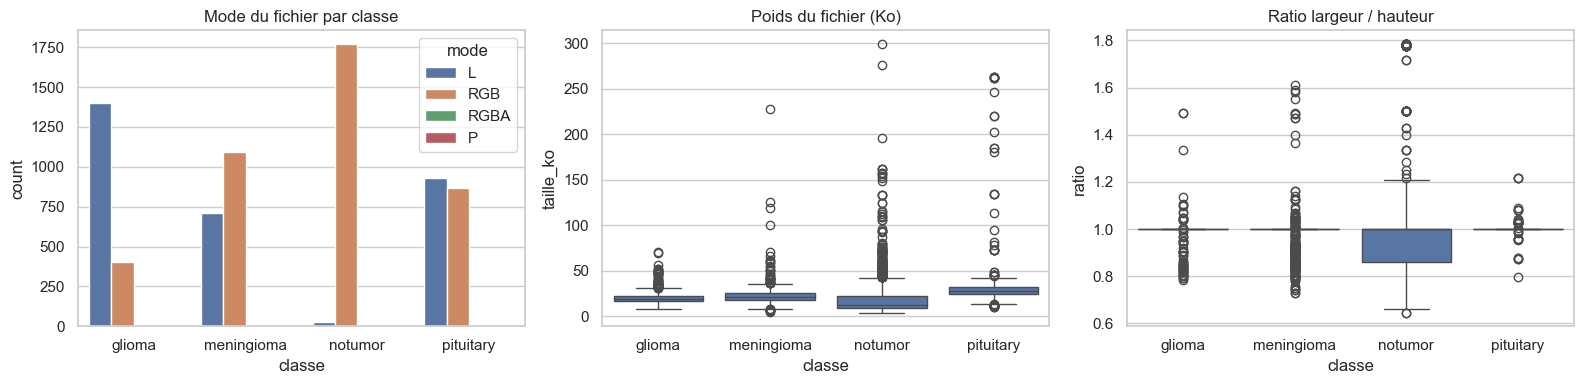

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(df, x="classe", hue="mode", order=CLASS_NAMES, ax=axes[0])
axes[0].set_title("Mode du fichier par classe")
sns.boxplot(df, x="classe", y="taille_ko", order=CLASS_NAMES, ax=axes[1])
axes[1].set_title("Poids du fichier (Ko)")
sns.boxplot(df, x="classe", y="ratio", order=CLASS_NAMES, ax=axes[2])
axes[2].set_title("Ratio largeur / hauteur")
plt.tight_layout(); plt.savefig(FIG / "eda_metadata_by_class.png", dpi=150); plt.show()

Ce qu’on lit

- Taille 512×512 : 96 % des glioma, 86 % des meningioma, 96 % des pituitary, mais seulement 1,1 % des notumor. Presque toutes les images saines ont donc une taille différente des autres classes.

- Images non carrées : 32 % des notumor sont carrées contre 88 à 98 % ailleurs. Autrement dit, les deux tiers des notumor ne sont pas carrés, alors que c’est rare dans les trois autres classes. Les ratios extrêmes (jusqu’à 1,79) sont presque tous des notumor.

- Mode : 98 % des notumor sont en RGB, contre 22 % des glioma. Le mode seul ne suffit pas à classer (meningioma et pituitary sont mélangés), mais combiné à la taille il sépare déjà très bien notumor.

- Poids du fichier : notumor a une médiane basse (12 Ko) mais une très grande dispersion, pituitary est plus lourd (28 Ko). Les classes n’ont pas le même profil de compression, ce qui indique des sources ou des exports différents.

**Conséquence de ce qu'on pourrait avoir si on ne fait pas attention** 

Un modèle pourrait reconnaître notumor sans regarder le cerveau : taille non carrée plus RGB plus image plus claire suffisent.

## 4. Exemples par classe

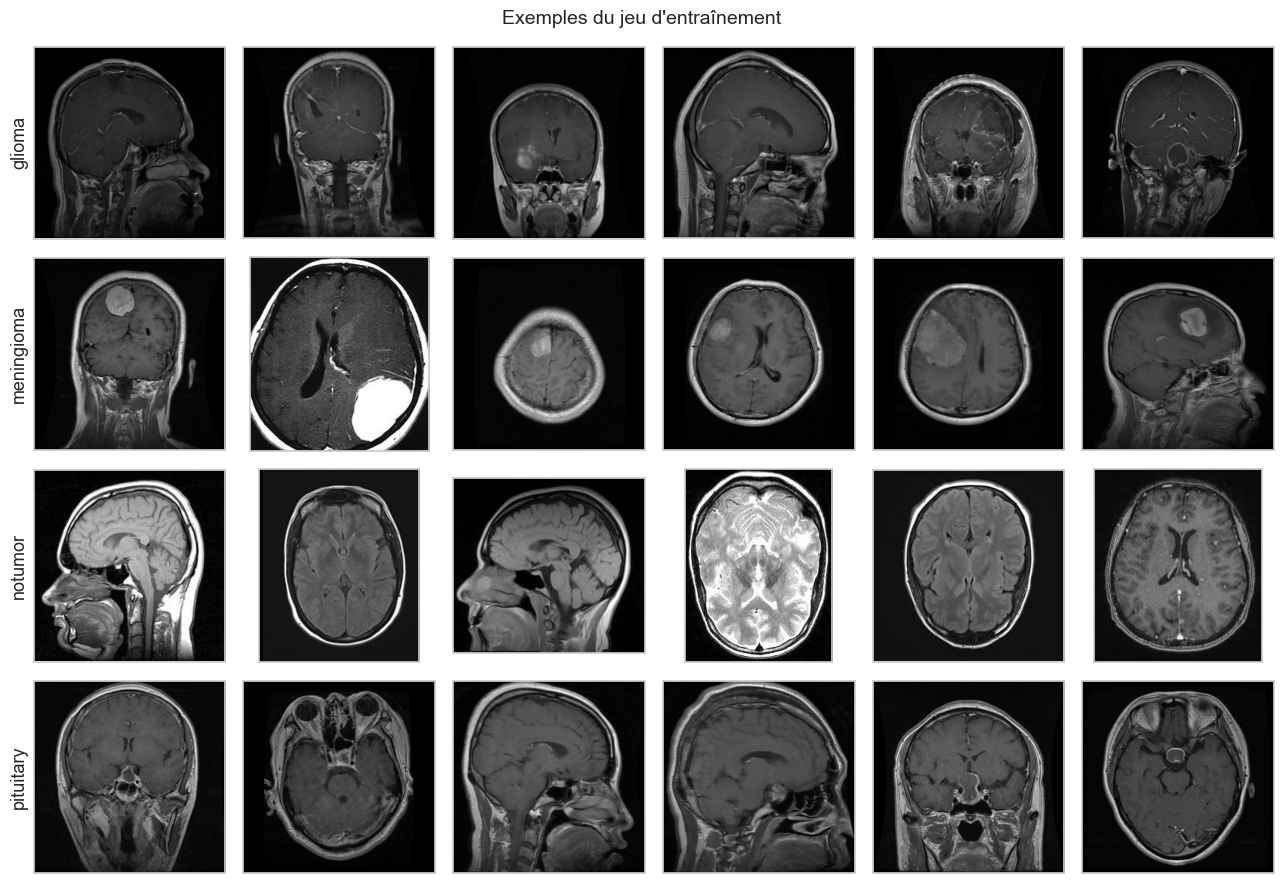

In [11]:
fig, axes = plt.subplots(4, 6, figsize=(13, 9))
for r, name in enumerate(CLASS_NAMES):
    for c, p in enumerate(df[(df.classe == name) & (df.split == "Training")].sample(6, random_state=1).path):
        axes[r, c].imshow(Image.open(p).convert("RGB"))  # affichée telle quelle, sans passage en gris
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(name, fontsize=13)
plt.suptitle("Exemples du jeu d'entraînement", fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "eda_samples.png", dpi=150); plt.show()

**Constats** :
- Les images sont affichées **telles quelles** (sans conversion en gris), y compris celles stockées en `RGB` : **aucune ne présente de couleur**. C'est normal : une IRM mesure **un seul signal par pixel** ; le RGB n'est qu'un format d'enregistrement où les 3 canaux portent la même valeur.
  → **décision : 1 canal**. Garder 3 canaux identiques n'apporterait aucune information et triplerait le calcul de la 1re couche.
- Plusieurs **plans de coupe** (axial, coronal, sagittal) et **séquences IRM** (T1, T2…) sont mélangés : le modèle doit généraliser à tous.
- Beaucoup d'images ont de **larges bords noirs** autour du crâne, et le cerveau n'occupe pas toujours la même place.
  → on **recadre sur le cerveau** avant de redimensionner, pour ne pas gaspiller de pixels.
- Certaines tumeurs (surtout *pituitary*) sont **petites** : il ne faut pas trop réduire la résolution.

## 5. Intensité des pixels

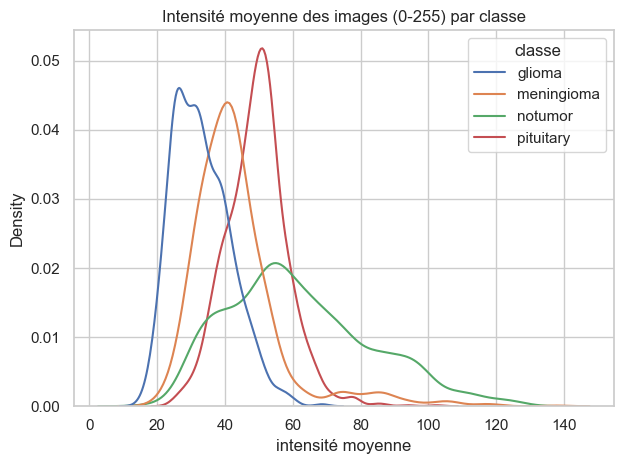

,count,mean,std,min,25%,50%,75%,max
classe,,,,,,,,
glioma,1400.0,33.1,8.5,14.9,26.2,31.9,38.8,68.8
meningioma,1400.0,43.4,13.8,18.2,35.1,41.0,47.0,137.8
notumor,1400.0,61.7,21.1,17.4,46.4,57.8,75.2,125.1
pituitary,1400.0,49.4,9.0,24.7,43.7,49.7,54.4,102.3


In [12]:
def mean_intensity(p):
    return np.asarray(Image.open(p).convert("L"), dtype=np.float32).mean()

train_df = df[df.split == "Training"].copy()
train_df["intensité moyenne"] = train_df["path"].apply(mean_intensity)
ax = sns.kdeplot(train_df, x="intensité moyenne", hue="classe", common_norm=False)
ax.set_title("Intensité moyenne des images (0-255) par classe")
plt.tight_layout(); plt.savefig(FIG / "eda_intensity.png", dpi=150); plt.show()
train_df.groupby("classe")["intensité moyenne"].describe().round(1)

**Constat** : les intensités varient beaucoup d'une image à l'autre (machines et séquences différentes), et sont sur une échelle 0-255.
→ on **normalise** : division par 255 puis standardisation de **chaque image** avec sa moyenne et son écart-type. Des entrées centrées et réduites stabilisent la descente de gradient.
→ on ajoute une **légère augmentation de luminosité/contraste** pendant l'entraînement pour rendre le modèle robuste à ces variations.

In [13]:
S = 224
SEUIL_NOIR = 20  # même seuil que crop_brain

sums = {c: np.zeros((S, S)) for c in CLASS_NAMES}
sqs = {c: np.zeros((S, S)) for c in CLASS_NAMES}
hists = {c: np.zeros(256) for c in CLASS_NAMES}
n = {c: 0 for c in CLASS_NAMES}
rows = []

for p, c in zip(df["path"], df["classe"]):
    img = Image.open(p).convert("L")
    g = np.asarray(img)
    gf = g.astype(np.float32)
    p1, p50, p99 = np.percentile(gf, [1, 50, 99])
    rows.append({
        "moy": gf.mean(), "ecart_type": gf.std(),
        "p1": p1, "p50": p50, "p99": p99, "max": gf.max(),
        "pct_noir": (g < SEUIL_NOIR).mean() * 100,
    })
    small = np.asarray(img.resize((S, S), Image.BILINEAR), dtype=np.float64)
    sums[c] += small
    sqs[c] += small ** 2
    hists[c] += np.bincount(g.ravel(), minlength=256) / g.size
    n[c] += 1

stats_cols = pd.DataFrame(rows, index=df.index)
df = df.drop(columns=[c for c in stats_cols.columns if c in df.columns]).join(stats_cols)

display(df.groupby("classe")[["moy", "ecart_type", "p1", "p50", "p99", "max", "pct_noir"]].mean().round(1))


,moy,ecart_type,p1,p50,p99,max,pct_noir
classe,,,,,,,
glioma,34.700001,39.299999,0.2,17.7,157.4,254.100006,53.1
meningioma,44.700001,47.200001,0.6,27.8,184.5,254.399994,49.1
notumor,61.400002,60.599998,2.6,39.6,223.5,251.199997,43.1
pituitary,49.400002,41.599998,0.1,46.5,173.1,254.300003,36.6


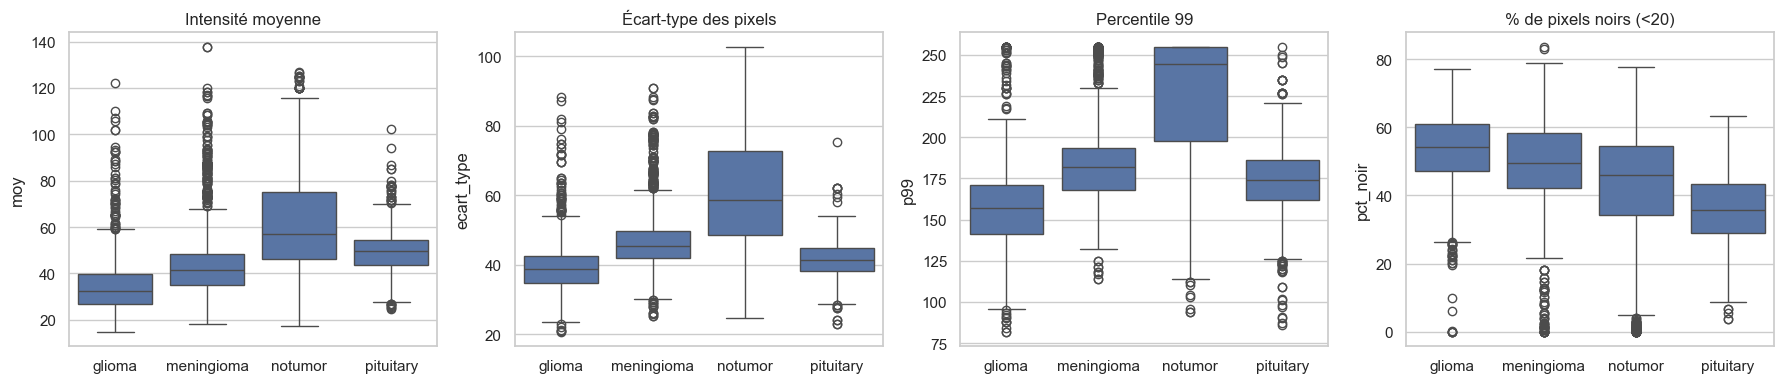

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col, titre in zip(axes, ["moy", "ecart_type", "p99", "pct_noir"],
                          ["Intensité moyenne", "Écart-type des pixels", "Percentile 99", "% de pixels noirs (<20)"]):
    sns.boxplot(df, x="classe", y=col, order=CLASS_NAMES, ax=ax)
    ax.set_title(titre); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "eda_intensity_stats.png", dpi=150); plt.show()

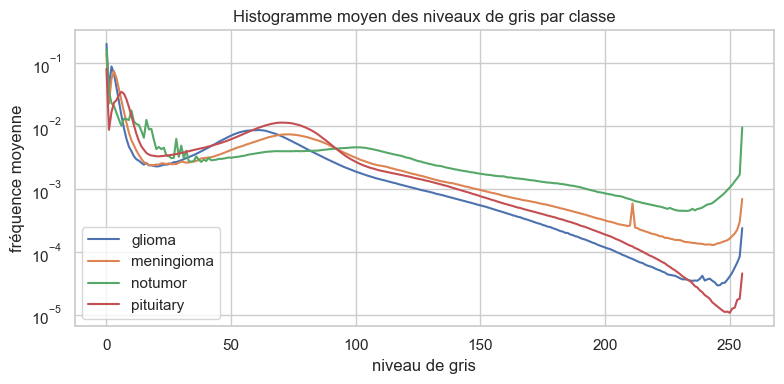

In [15]:
plt.figure(figsize=(8, 4))
for c in CLASS_NAMES:
    plt.plot(hists[c] / n[c], label=c)
plt.yscale("log"); plt.xlabel("niveau de gris"); plt.ylabel("fréquence moyenne")
plt.title("Histogramme moyen des niveaux de gris par classe"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "eda_mean_histogram.png", dpi=150); plt.show()

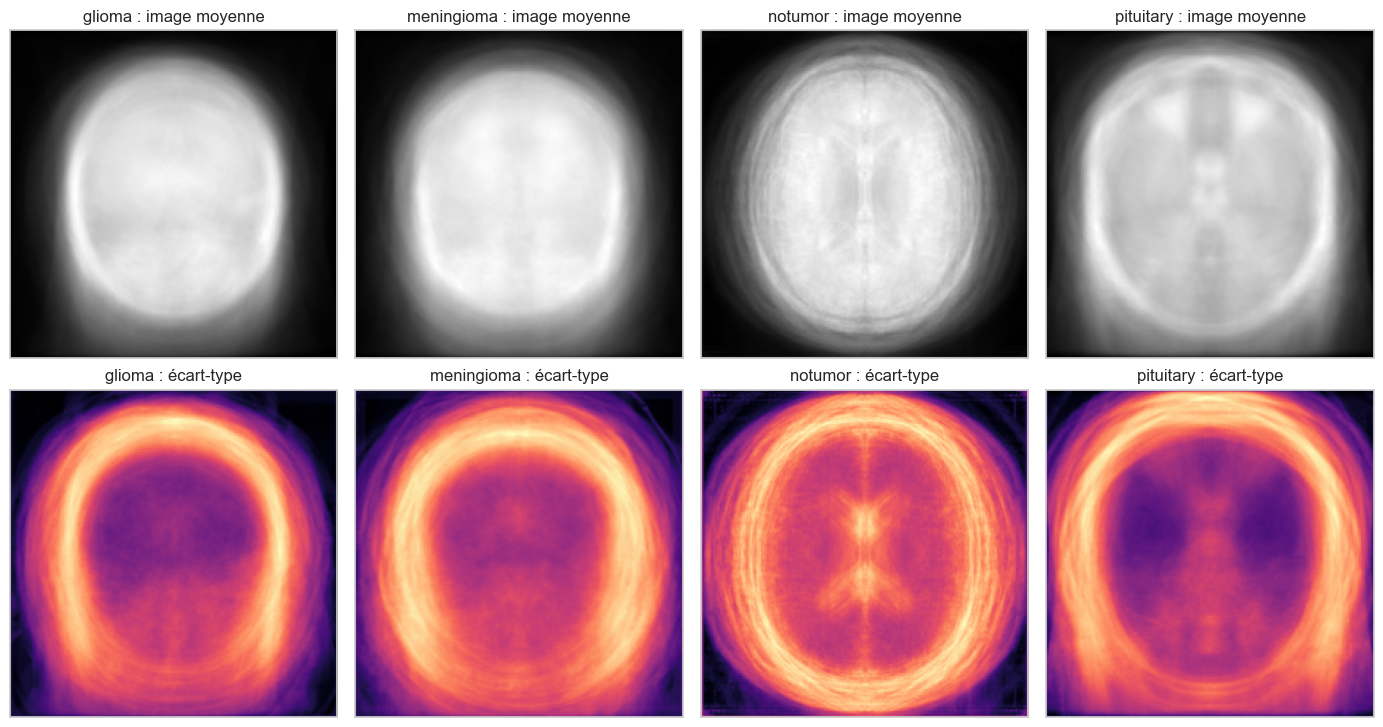

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for j, c in enumerate(CLASS_NAMES):
    mean_img = sums[c] / n[c]
    std_img = np.sqrt(sqs[c] / n[c] - mean_img ** 2)
    axes[0, j].imshow(mean_img, cmap="gray"); axes[0, j].set_title(f"{c} : image moyenne")
    axes[1, j].imshow(std_img, cmap="magma"); axes[1, j].set_title(f"{c} : écart-type")
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(FIG / "eda_mean_images.png", dpi=150); plt.show()

Le biais de source est maintenant visible dans les pixels, pas seulement dans les fichiers. Et les images moyennes montrent quelque chose de plus gênant : le plan de coupe est lui aussi très lié à la classe

Notumor se distingue sur presque tout : taille du fichier, mode, ratio, intensité, contraste, saturation, plan de coupe, cadre. Un modèle pourrait atteindre un bon score sur cette classe sans regarder de tumeur.

Pour la suite, il faudra regarder les métriques par classe et pas seulement l’accuracy globale.

## 6. Doublons

In [17]:
df["hash"] = df["path"].apply(lambda p: hashlib.md5(Path(p).read_bytes()).hexdigest())
groups = df.groupby("hash").agg(n=("path", "size"), splits=("split", "nunique"), classes=("classe", "nunique"))
dups = groups[groups.n > 1]
print(f"Groupes de doublons exacts : {len(dups)}  ({dups.n.sum()} images concernées)")
print(f"  - entre Training et Testing : {(dups.splits > 1).sum()}")
print(f"  - avec des labels différents : {(dups.classes > 1).sum()}")
df[df.hash.isin(dups.index)].groupby(["split", "classe"]).size().rename("images en double")

Groupes de doublons exacts : 153  (340 images concernées)
  - entre Training et Testing : 0
  - avec des labels différents : 0


split     classe    
Testing   glioma         27
          meningioma      4
Training  meningioma     27
          notumor       216
          pituitary      66
Name: images en double, dtype: int64

**Constat** : il y a des **doublons exacts** à l'intérieur des splits, mais **aucun entre Training et Testing** et **aucun conflit de label**.
→ on supprime les doublons de Training **avant** de le découper en train/validation : sinon une même image pourrait être à la fois en train et en validation, ce qui gonflerait artificiellement le score de validation.
→ on garde Testing tel quel (c'est le jeu de test officiel).

Limite du MD5 : il ne repère que les fichiers **strictement** identiques. La même IRM enregistrée à une autre taille ou avec une autre compression a une empreinte différente. On cherche donc aussi les **quasi-doublons** dans le notebook 02, une fois toutes les images ramenées à la même taille.

## 7. Training vs Testing

On vérifie que le test ressemble au train, classe par classe.

In [18]:
comp = df.assign(rgb=df["mode"].eq("RGB")).groupby(["classe", "split"])[["rgb", "std512", "carree"]]
comp.mean().mul(100).round(1).unstack("split")

rgb           std512           carree         
split      Testing Training Testing Training Testing Training
classe                                                       
glioma        43.5     16.2    81.0    100.0    83.8    100.0
meningioma    61.5     60.4    70.8     90.5    75.5     91.9
notumor       98.5     98.1     0.8      1.2    30.0     32.8
pituitary     19.2     56.6    98.0     94.9   100.0     97.5

Le test a **le même biais** que le train : les notumor du test sont aussi presque toutes en RGB, rarement en 512x512 et souvent pas carrées. Donc si le modèle utilise ce raccourci, il marchera aussi sur le test. Un bon score de test ne prouve pas à lui seul que le modèle regarde la tumeur, d'où l'intérêt de Grad-CAM et des métriques par classe.

## 8. Projection 2D des pixels



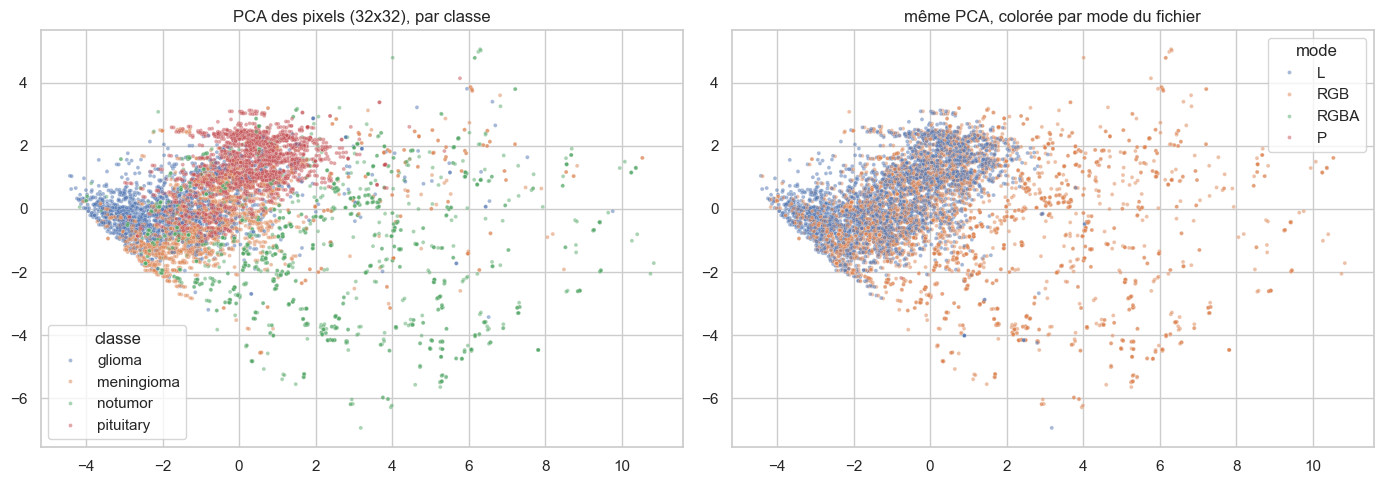

In [19]:
X = np.stack([np.asarray(Image.open(p).convert("L").resize((32, 32), Image.BILINEAR), dtype=np.float32).ravel() / 255
              for p in df["path"]])
Z = PCA(n_components=2, random_state=0).fit_transform(X)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df["classe"], s=8, alpha=0.5, ax=axes[0])
axes[0].set_title("PCA des pixels (32x32), par classe")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df["mode"], s=8, alpha=0.5, ax=axes[1])
axes[1].set_title("même PCA, colorée par mode du fichier")
plt.tight_layout(); plt.savefig(FIG / "eda_pca.png", dpi=150); plt.show()

Sur les pixels bruts, notumor se distingue des trois autres classes, et le premier axe de la PCA suit le mode du fichier, ce qui renforce l’hypothèse d’une source différente. Les trois classes tumorales restent très mélangées.

## 9. Limites du dataset

- **Pas d'identifiant patient** : un même patient a souvent plusieurs coupes très proches. On ne peut pas les séparer proprement entre train, validation et test, donc les scores peuvent être un peu optimistes.
- **notumor vient d'une autre source** (format, taille, luminosité, plans de coupe). Le modèle peut apprendre la source au lieu de l'absence de tumeur.
- **Doublons dans le test officiel** (16 images en trop, en glioma et meningioma) : on les garde pour respecter le jeu de test d'origine, mais elles comptent double dans le score.
- **Quasi-doublons** : on retire les copies d'une même image (notebook 02), mais pas les coupes voisines d'un même patient, qu'on ne peut pas distinguer sans identifiant. Quelques copies retouchées (contraste modifié) peuvent aussi passer sous le radar.
- On n'a pas testé de rehaussement d'image (CLAHE, débruitage) : les images sont déjà nettes et le CNN apprend lui-même à gérer le contraste.

## 10. Bilan → choix de prétraitement

| Constat | Choix |
|---|---|
| Tailles très variables (150 → 1 400 px, majorité 512) | Redimensionnement à **224×224** : assez de détail pour les petites tumeurs, coût de calcul raisonnable, taille standard en vision |
| Images non carrées | **Padding** noir jusqu'à un carré avant redimensionnement (pas de déformation) |
| Larges bords noirs | **Recadrage** automatique sur le cerveau |
| Aucune couleur visible sur les images (une IRM est monochrome) | **1 canal** |
| Intensités 0-255 très variables | **/255 puis standardisation par image** (efface les écarts de luminosité entre sources) |
| Classes équilibrées au départ, mais notumor perd beaucoup d'images au nettoyage | Pondération de la loss testée (pas de gain) ; on suit le rappel par classe |
| Doublons exacts et quasi-doublons, dont des copies d'images du test | **Suppression** dans Training avant le découpage ; test officiel gardé tel quel |
| notumor vient d'une autre source, et le test a le même biais | **Métriques par classe** + **Grad-CAM** pour vérifier ce que regarde le modèle |
| Pas de jeu de validation fourni | **15 % de Training** (stratifié) pour les callbacks et l'optimisation ; Testing réservé à l'évaluation finale |

La mise en œuvre est dans `src/load_data.py` et illustrée dans `02-preproc.ipynb`.